# JavaScript Performance Playbook


A practical guide to measuring and improving JavaScript application performance. Covers fundamentals, memory management and DOM optimization, and async execution patterns — with concrete techniques you can apply immediately.


## Table of Contents

- [Module 01: Understanding JavaScript Performance Fundamentals](#module-01)
- [Module 02: Memory Management and DOM Optimization](#module-02)
- [Module 03: Optimizing JavaScript Execution](#module-03)


In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))


<a id="module-01"></a>
## Module 01: Understanding JavaScript Performance Fundamentals

_An overview of best practices, modernization strategies, and tools for improving JavaScript performance._


### 5 Best Practices for Improving JavaScript Performance

1. **Minify and compress your JavaScript files** — reduces file size transferred over the network
2. **Use a Content Delivery Network (CDN)** — serves files from nodes geographically close to the user
3. **Load JavaScript files asynchronously** — prevents scripts from blocking page rendering

```html
<script src="script_a.js" async></script>
```

4. **Use caching** — avoids re-fetching unchanged resources on repeat visits
5. **Use a JavaScript framework** — mature frameworks bake in many optimisations by default


### Modernizing Legacy JavaScript Code

Modernising legacy code helps JavaScript engines optimise execution more effectively. Five strategies:

| Strategy | What to do | Why it helps |
|---|---|---|
| **Use modern features** | Arrow functions, `let`/`const`, template literals, destructuring, `async`/`await` | More concise, easier for engines to optimise |
| **Reduce redundant code** | Remove unused variables, dead branches, duplicate logic | Smaller parse/compile surface area |
| **Improve variable naming** | Use clear, descriptive names | Aids developers in spotting optimisation opportunities |
| **Refactor legacy patterns** | Replace outdated constructs with modern equivalents | Eliminates anti-patterns that inhibit engine optimisation |
| **Update dependencies** | Keep libraries at their latest stable versions | Leverage performance improvements in newer releases |


### Tools for Improving JavaScript Performance

| Tool | Description | URL |
|---|---|---|
| **jsPerf** | Online JavaScript performance benchmark runner — compare code snippet performance across browsers | https://jsperf.app |
| **jsDelivr** | Free CDN for open-source projects — serve libraries from a global edge network | https://jsdelivr.com |
| **BulatsQ Tips-Tools** | Performance tips and utilities for JavaScript tooling | — |
| **Lighthouse** | Google Chrome DevTools and CLI — audits performance, accessibility, and best practices | https://developers.google.com/speed/pagespeed/insights |
| **Online YUI Compressor** | Compress JS and CSS files online or via CLI | https://yui.github.io/yuicompressor / https://www.piliapp.com/minify/yui-compressor |
| **JS Minify (UglifyJS)** | Minifies JavaScript to improve site speed and accessibility | https://amp.uglifyjs.net |

<a id="module-02"></a>
## Module 02: Memory Management and DOM Optimization

_How JavaScript manages memory, how to identify and fix memory leaks, how DOM interactions affect performance, and how variable scope affects memory usage._


### Handling Memory Leaks

#### What Is a Memory Leak?

A memory leak occurs when memory that is no longer needed by the application is not returned to the operating system or the pool of free memory. Over time this causes the application to consume increasing amounts of RAM, slowing down or crashing.

#### How JavaScript Manages Memory

JavaScript is a **garbage-collected** language. The engine periodically checks which previously allocated memory is still reachable from the application and frees anything that is not. The key implication: you cannot manually free memory, but you can accidentally keep objects reachable longer than needed.

#### Three Common JavaScript Memory Leaks

1. **Forgotten timers or callbacks** — a `setInterval` or event listener that holds a reference to objects even after they are no longer needed
2. **Accidental global variables** — assigning to an undeclared variable creates a global that persists for the lifetime of the page
3. **Out-of-DOM references** — storing a reference to a DOM node in a JavaScript variable and then removing the node from the DOM; the node cannot be garbage-collected as long as the variable holds it

#### Handling Memory Leaks: Detect, Diagnose, Remediate

| Phase | Approach |
|---|---|
| **Detect** | Chrome DevTools Memory panel or APM tools (e.g. Datadog) to spot heap growth over time |
| **Diagnose** | Heap snapshots and allocation profiling to pinpoint which objects are accumulating |
| **Remediate** | Fix the code — clear timers, remove event listeners, null-out stale references |


### Optimizing the DOM

#### Why the DOM Affects Performance

Every time JavaScript adds, removes, or modifies a DOM element, the browser recalculates the page layout — a potentially expensive operation called **reflow**. Frequent DOM mutations can block the main thread and cause visible sluggishness.

#### Three Ways to Optimise DOM Interactions

| Technique | What it means | Why it helps |
|---|---|---|
| **Cache DOM references** | Store the result of `document.querySelector(...)` in a variable rather than querying on every use | Avoids repeated document traversals |
| **Batch DOM interactions** | Group multiple DOM changes into a single operation (e.g. using `DocumentFragment` or updating a hidden element) | Reduces the number of reflows |
| **Event delegation** | Attach one event listener to a parent element instead of individual listeners on each child | Fewer listeners, less memory, works for dynamically added children |

> Minimising DOM access, size, and element count is the simplest way to keep rendering fast.


### Variable Scope and Performance

#### Why Scope Matters for Performance

The JavaScript engine resolves variable names by walking up the scope chain. The deeper a variable is in an outer scope, the longer the lookup takes. Keeping variables in the narrowest possible scope improves both performance and maintainability.

#### The Three Scope Types in JavaScript

| Scope | Declared with | Accessible where |
|---|---|---|
| **Global** | Outside any function or block | Anywhere in the code — persists for the page lifetime |
| **Function** | `var` inside a function | Within that function only |
| **Block** | `let` or `const` inside `{}` braces | Within that block only |

#### Best Practices for Scope Management

- **Minimise global variables** — globals create the widest possible scope chain lookup and risk name collisions across files
- **Encapsulate code in functions or blocks** — creates local scopes, reduces lookup depth, and makes code more modular
- **Avoid hoisting surprises** — prefer `let`/`const` over `var` so variables do not escape their intended scope


<a id="module-03"></a>
## Module 03: Optimizing JavaScript Execution

_Understanding synchronous versus asynchronous execution and applying practical techniques to improve responsiveness and reduce timeout-related performance issues._


### Synchronous vs. Asynchronous Code

#### The Core Difference

| | Synchronous | Asynchronous |
|---|---|---|
| **Execution model** | Line by line; each operation must complete before the next starts | Operations can be initiated and other work continues while waiting for completion |
| **Thread impact** | Blocks the main thread during long operations | Frees the main thread to handle rendering and user input |
| **Best for** | Simple sequential logic | I/O-bound work: network requests, file reads, database queries, timers |



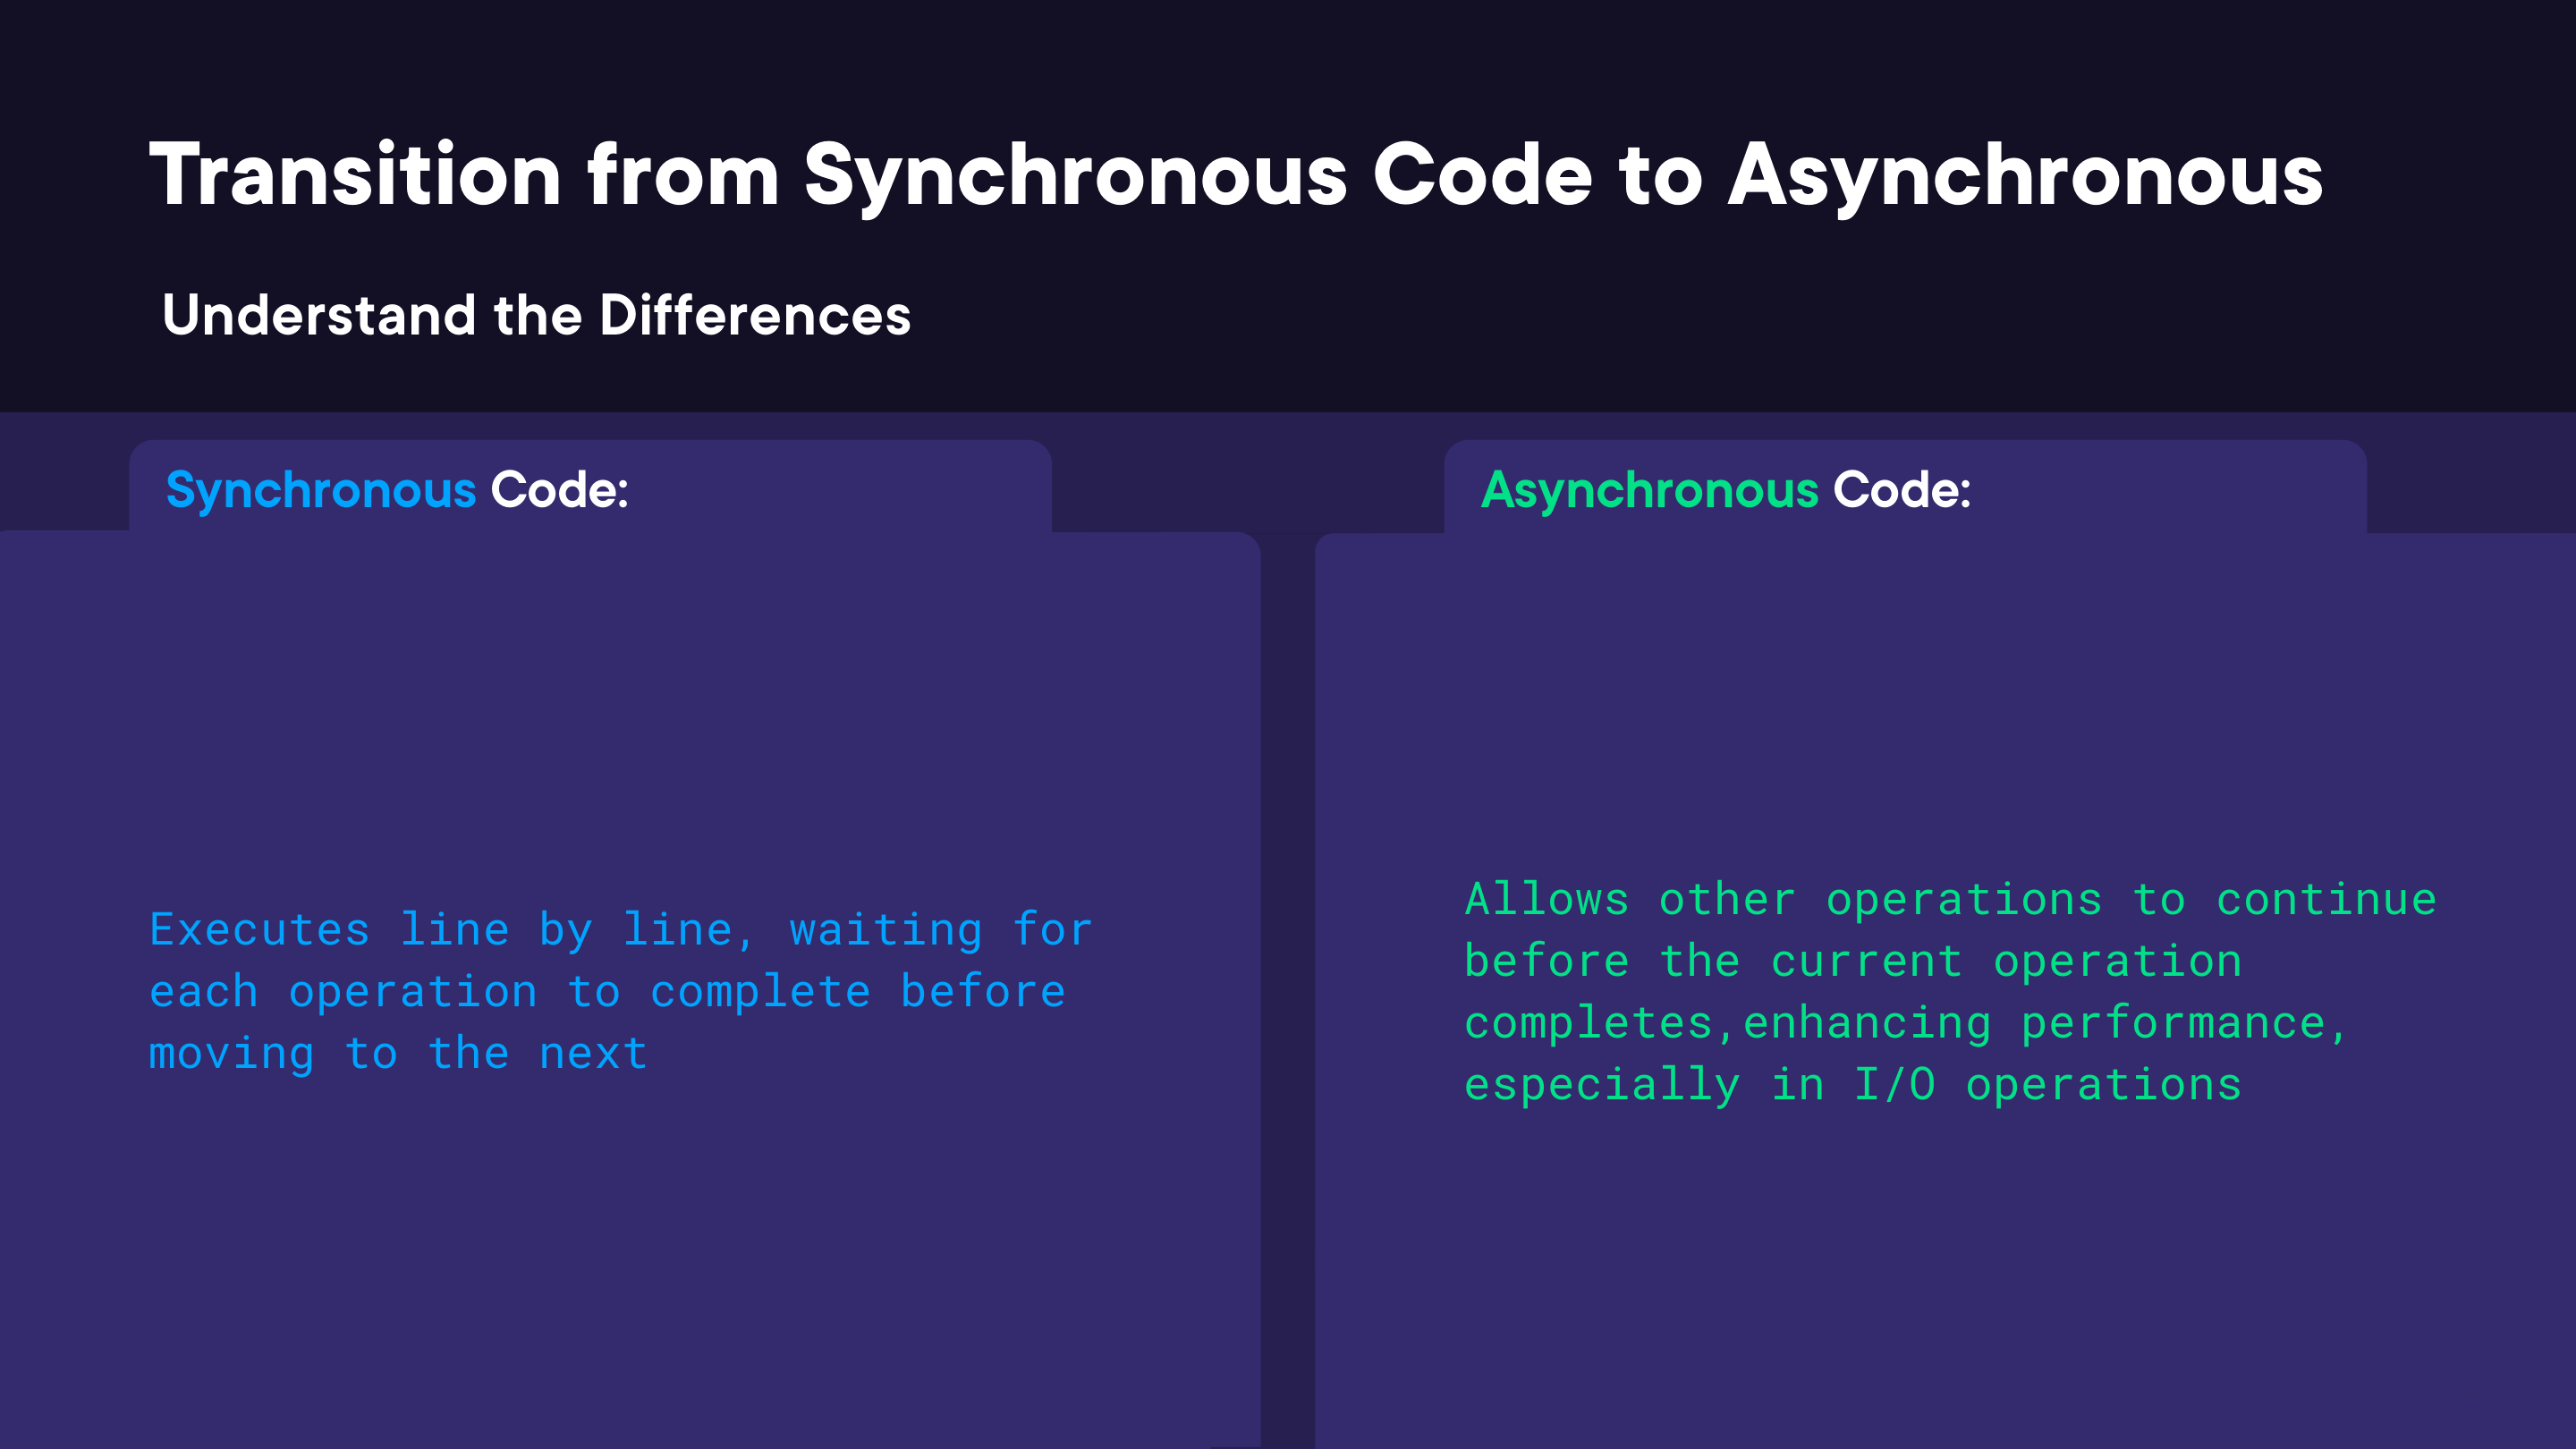

In [2]:
render_diagram(Path("assets/01-sync-vs-async-comparison.png"))

#### Identifying Synchronous Bottlenecks

Look for these patterns as candidates for async conversion:

- Network requests (HTTP calls)
- File system operations
- Database queries
- Long-running computations

#### Converting to Async: Promises and async/await

A **Promise** represents the eventual completion (or failure) of an asynchronous operation. `async`/`await` syntax makes working with Promises look like synchronous code, improving readability while keeping execution non-blocking.



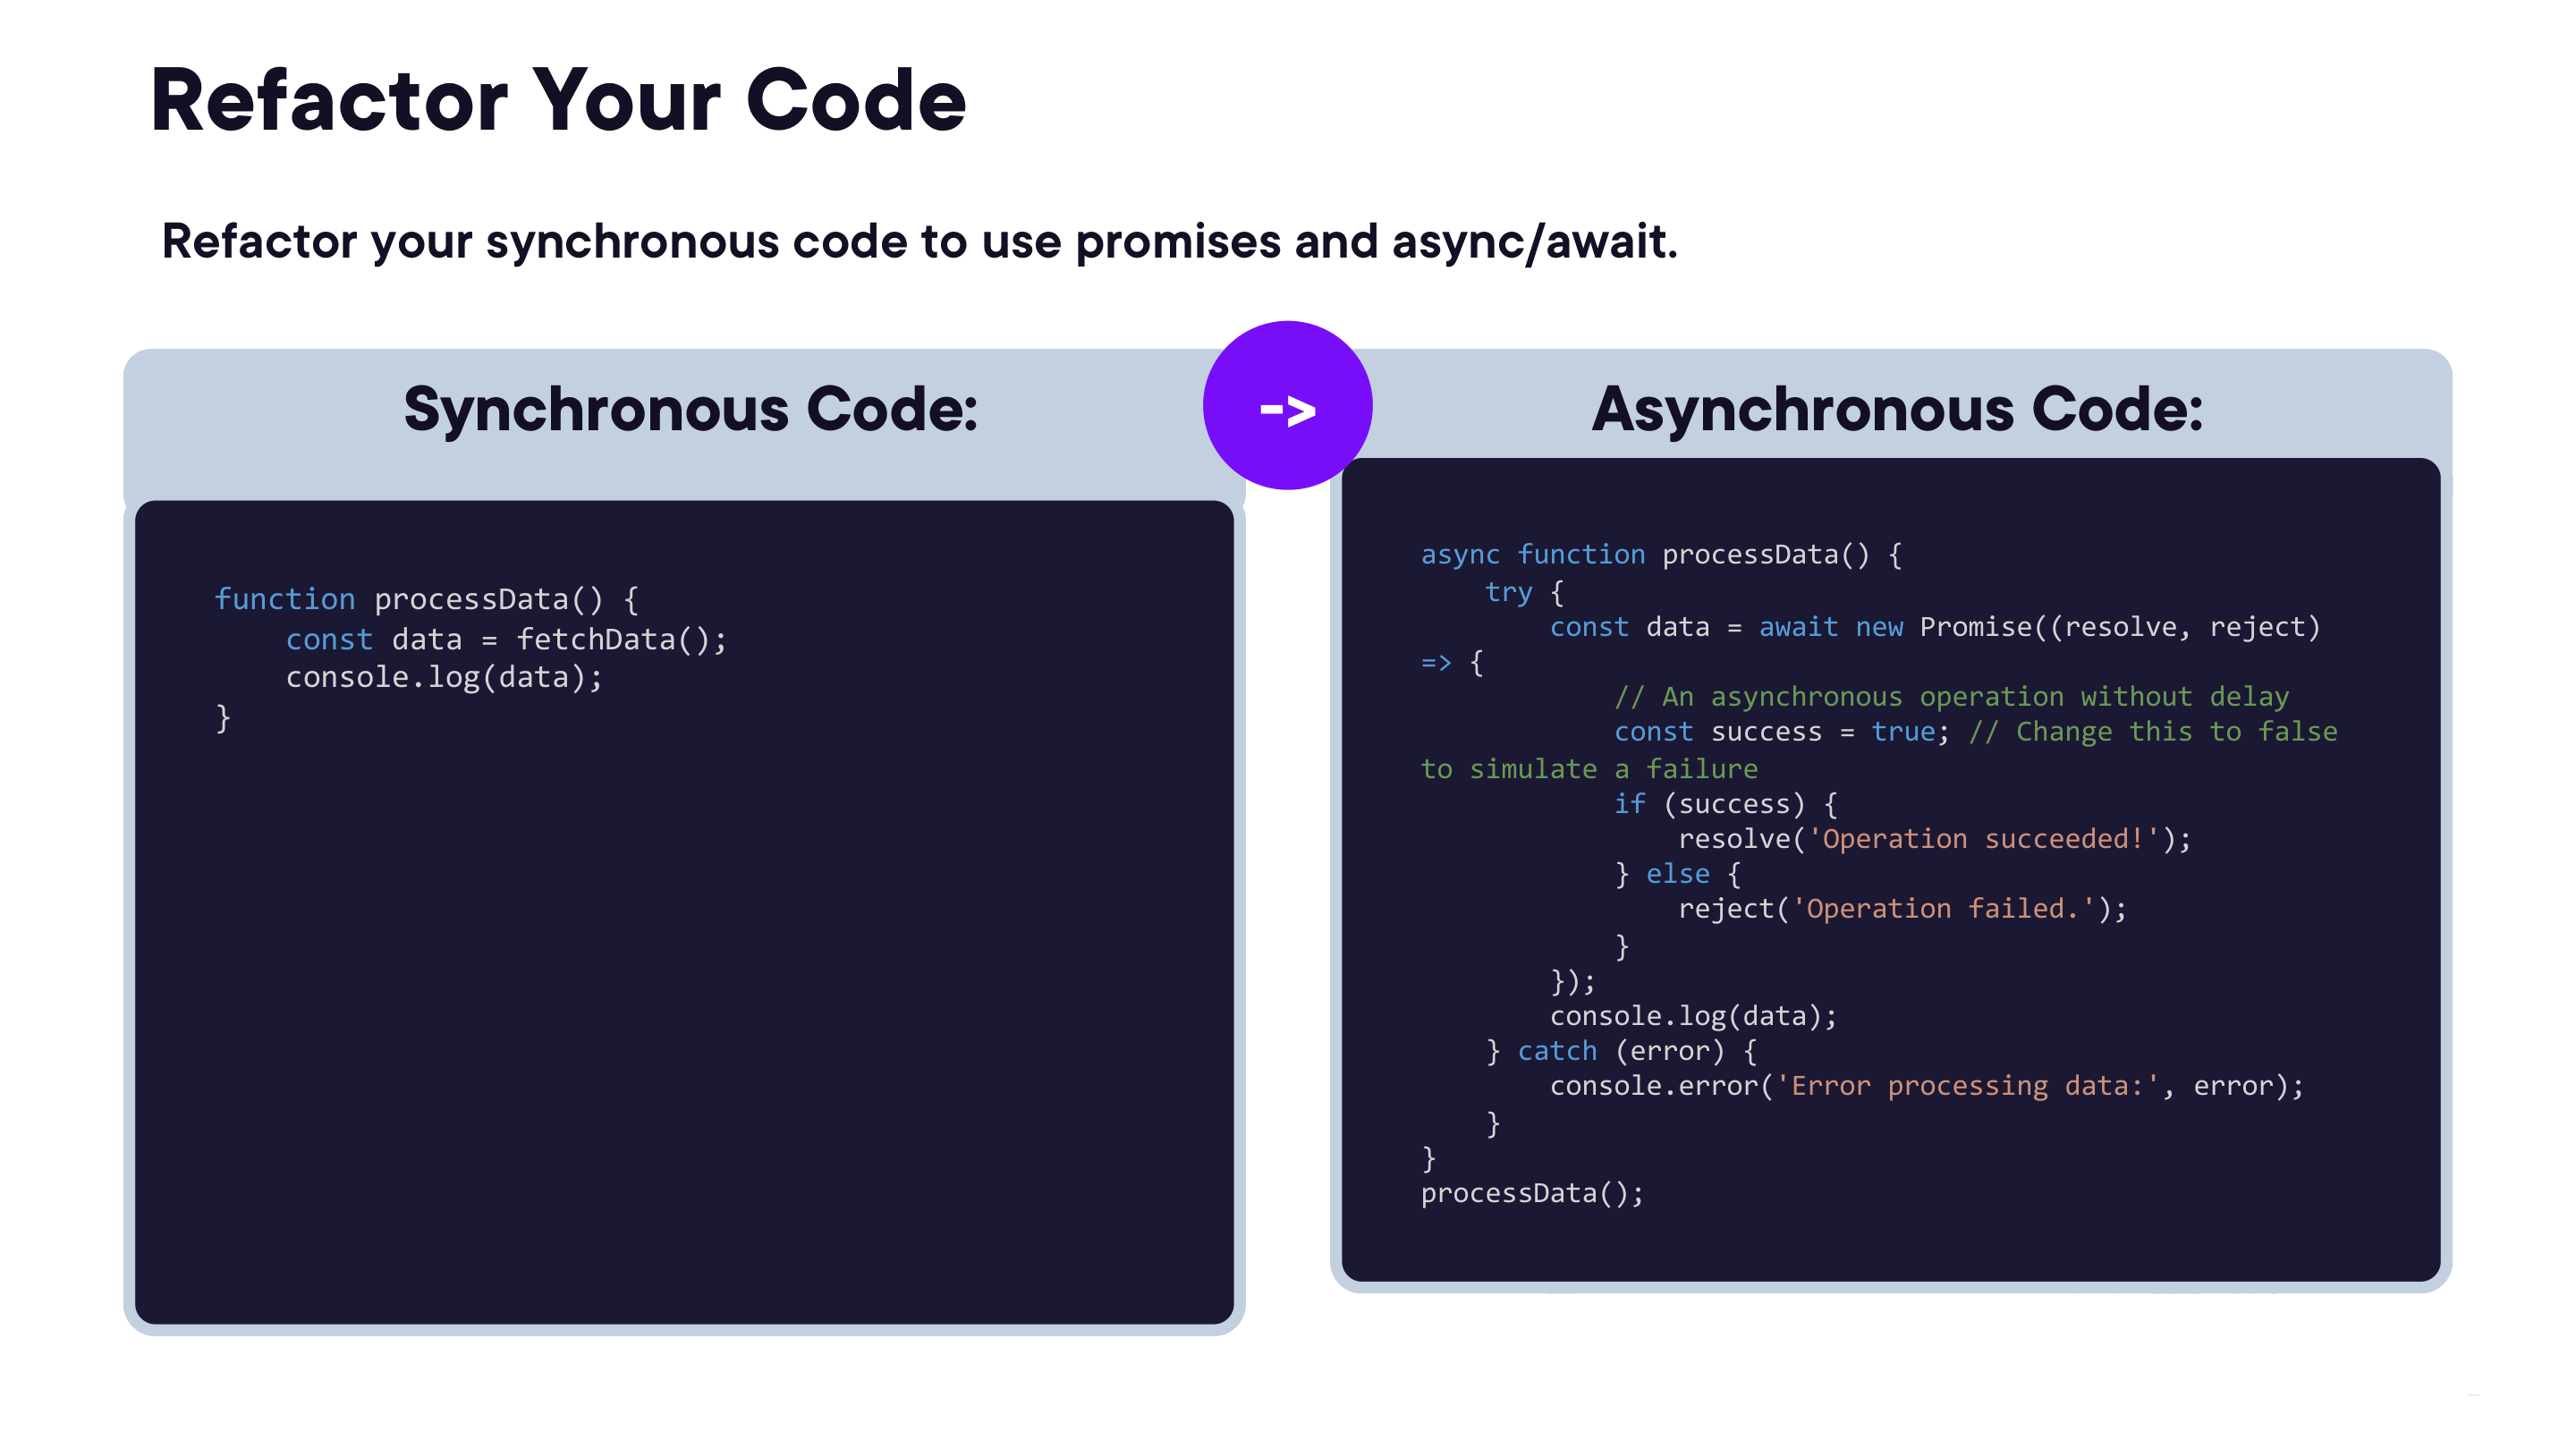

In [3]:
render_diagram(Path("assets/02-sync-async-code-refactor.png"))

#### Refactoring Pattern: Sync to Async/Await

```javascript
// Before — synchronous (blocks while fetchData() runs)
function processData() {
  const data = fetchData();
  console.log(data);
}

// After — async/await with error handling
async function processData() {
  try {
    const data = await new Promise((resolve, reject) => {
      const success = true;
      if (success) {
        resolve('Operation succeeded!');
      } else {
        reject('Operation failed.');
      }
    });
    console.log(data);
  } catch (error) {
    console.error('Error processing data:', error);
  }
}

processData();
```


### Improving Responsiveness

Three techniques for keeping the main thread responsive:

| Technique | What it does | When to use |
|---|---|---|
| **Throttling** | Ensures a function is called at most once per specified time period | Window resize, scroll, mousemove handlers |
| **Debouncing** | Delays execution until a specified time has elapsed since the last invocation | Search input, form validation on keypress |
| **Reducing loop activity** | Optimise loop logic, minimise DOM manipulations inside loops, use efficient data structures | Any tight loop that touches the DOM or processes large arrays |

These techniques minimise the time the main thread is blocked, keeping rendering and user interaction smooth.


### Reducing Timeouts

Four strategies to prevent JavaScript from keeping the user waiting:

#### Caching Objects

Store frequently accessed data in a temporary in-memory location so future requests are served without a round trip to the server or database.

- **Reduces load times** — eliminates repeated network requests for unchanged data
- **Improves throughput** — memory access is orders of magnitude faster than a database or API call

#### Limiting Library Dependencies

Minimise the number of external libraries your code relies on, using only what is essential.

- **Decreases initial load time** — fewer files to download and parse
- **Reduces complexity** — a leaner dependency tree is easier to audit and less likely to introduce bottlenecks

#### Delaying JavaScript Loading

Use `defer` or `async` on script tags so non-critical JavaScript does not block the initial render.

```html
<!-- deferred: runs after HTML is parsed -->
<script src="analytics.js" defer></script>

<!-- async: runs as soon as downloaded, in parallel with parsing -->
<script src="widget.js" async></script>
```

- **Improves perceived load time** — users see content sooner
- **Prevents render-blocking** — page renders without waiting for all scripts

#### Using File Compression

Apply gzip or Brotli compression at the server level to reduce transfer size of JavaScript files.

- **Faster downloads** — smaller payloads transfer quicker on any connection
- **Reduced bandwidth** — particularly impactful for users on slow or metered connections
